# Failure Modes in Chained Tool-Calling Agents Operating Without Human Checkpoints
**Companion notebook** for the IEEEtran paper by Sachin Kumar (IIIT Allahabad, MRA2026004).

This notebook reproduces the paper's quantitative parts:
1. Independent-step compounding, $P=p^n$ (Eq. 1)
2. Monte Carlo trajectory simulation: 8 horizons × 3 control modes × 1,000 trials = **24,000 trajectories** (Table V, Fig. 4)
3. Adaptive risk score $R_t=\sigma(\alpha U+\beta I+\gamma P+\delta C)$ (Eq. 6) and its three-zone policy
4. Reliability vector $\mathbf{R}$ (Eq. 5) skeleton
5. *(Optional)* compile the `.tex` paper inside Colab

> Run cells top to bottom. Values will be close to, but not identical to, the paper's table, because Monte Carlo output depends on the seed and on the exact heuristics for divergence, detection and risk signals. Cell 4 lists the assumptions explicitly, so you can tune them and re-sync the paper's numbers.

In [9]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi":120,"font.size":10})

## 1. Independent-step compounding (Eq. 1)

p=0.9:  n=10 -> 0.349   n=50 -> 0.005
p=0.95:  n=10 -> 0.599   n=50 -> 0.077
p=0.99:  n=10 -> 0.904   n=50 -> 0.605


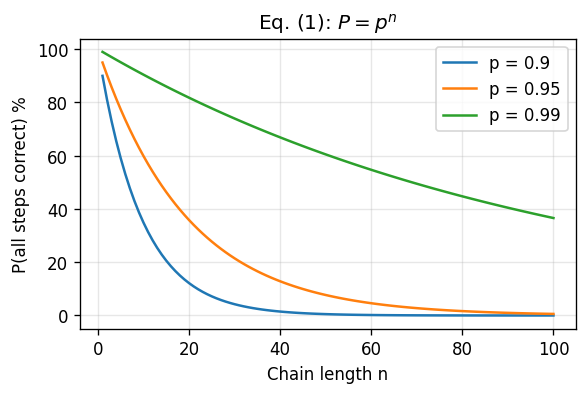

In [10]:
n = np.arange(1, 101)
for p in (0.90, 0.95, 0.99):
    print(f"p={p}:  n=10 -> {p**10:.3f}   n=50 -> {p**50:.3f}")

plt.figure(figsize=(5,3.4))
for p in (0.90, 0.95, 0.99):
    plt.plot(n, 100*p**n, label=f"p = {p}")
plt.xlabel("Chain length n"); plt.ylabel("P(all steps correct) %"); plt.legend(); plt.grid(alpha=.3)
plt.title("Eq. (1): $P = p^n$"); plt.tight_layout(); plt.show()

## 2. Simulation parameters
Taken from the paper: `p_base=0.95`, `Δp=0.40`, 20 % irreversible tools, `τ_escalate=0.70`, 1,000 trials per horizon and mode.

**Assumptions I had to make** (the paper doesn't pin these down; edit freely):
- Once a trajectory has *diverged* (an undetected error is in the state), per-step accuracy drops to `p_base − Δp`.
- A human checkpoint detects and resets a diverged state with probability `DETECT = 0.80`.
- An *irreversible error* = an erroneous step that uses an irreversible tool.
- **Task success** = trajectory is not in a diverged state at the end. **Divergence rate** = an error occurred at any point.
- Adaptive uncertainty `U_t` is a noisy signal that rises when the state is diverged.

In [11]:
P_BASE, DELTA_P, IRREV_FRAC, TAU_ESCALATE = 0.95, 0.40, 0.20, 0.70
DETECT   = 0.80
HORIZONS = [5, 10, 15, 20, 25, 30, 40, 50]
TRIALS   = 1000
SEED     = 42

# Risk-score coefficients (Eq. 6) -- heuristic, as stated in Future Work
ALPHA, BETA, GAMMA, DELTA, BIAS = 1.5, 3.3, 0.6, 0.6, -2.9

sigmoid = lambda x: 1.0 / (1.0 + np.exp(-x))

## 3. Risk score and three-zone policy (Eq. 6)

In [12]:
def risk_score(U, I, P, C):
    return sigmoid(ALPHA*U + BETA*I + GAMMA*P + DELTA*C + BIAS)

TAU_AUTO = 0.40  # execute autonomously below this; machine-verify between; human above TAU_ESCALATE
def zone(R):
    if R < TAU_AUTO:       return "auto"
    if R < TAU_ESCALATE:   return "machine-verify"
    return "escalate-to-human"

examples = {
 "read-only query":       dict(U=0.15, I=0.0, P=0.2, C=0.1),
 "update, mid-privilege": dict(U=0.30, I=0.5, P=0.5, C=0.4),
 "DROP TABLE, uncertain": dict(U=0.70, I=1.0, P=0.9, C=0.9),
}
for k, v in examples.items():
    R = risk_score(**v); print(f"{k:24s} R={R:.3f} -> {zone(R)}")

read-only query          R=0.076 -> auto
update, mid-privilege    R=0.435 -> machine-verify
DROP TABLE, uncertain    R=0.926 -> escalate-to-human


## 4. Trajectory simulator

In [13]:
def run_trajectory(n, mode, rng):
    diverged = False   # undetected error currently in state
    ever = False       # any error at any time
    irr_err = 0
    humans = 0
    for t in range(1, n+1):
        irreversible = rng.random() < IRREV_FRAC

        # --- adaptive: compute risk before acting, escalate if needed
        if mode == "adaptive":
            U = np.clip(0.15 + 0.45*diverged + rng.normal(0, 0.1), 0, 1)
            P = rng.random(); C = rng.random()
            R = risk_score(U, float(irreversible), P, C)
            if R >= TAU_ESCALATE:
                humans += 1
                if diverged and rng.random() < DETECT:
                    diverged = False

        # --- agent step
        p = P_BASE - DELTA_P if diverged else P_BASE
        if rng.random() > p:
            diverged = True; ever = True
            if irreversible: irr_err += 1

        # --- fixed periodic checkpoint
        if mode == "fixed5" and t % 5 == 0:
            humans += 1
            if diverged and rng.random() < DETECT:
                diverged = False
    return (not diverged), ever, irr_err, humans

def simulate(seed=SEED):
    rng = np.random.default_rng(seed)
    rows = []
    for n in HORIZONS:
        for mode in ("none", "fixed5", "adaptive"):
            res = np.array([run_trajectory(n, mode, rng) for _ in range(TRIALS)], float)
            rows.append(dict(n=n, mode=mode,
                             success_pct=100*res[:,0].mean(),
                             divergence_pct=100*res[:,1].mean(),
                             irreversible_per_traj=res[:,2].mean(),
                             human_interventions=res[:,3].mean()))
    return pd.DataFrame(rows)

df = simulate()
print(f"Total trajectories simulated: {len(HORIZONS)*3*TRIALS:,}")

Total trajectories simulated: 24,000


## 5. Results table (cf. Table V)

In [14]:
label = {"none":"None","fixed5":"Fixed-5","adaptive":"Adaptive"}
show = df.assign(mode=df["mode"].map(label)).round(3)
show.columns = ["n","Control","Success %","Divergence %","Irreversible/traj","Human interv."]
display(show.set_index(["n","Control"]))

Success %  Divergence %  Irreversible/traj  Human interv.
n  Control                                                            
5  None           77.2          22.8              0.088          0.000
   Fixed-5        94.6          23.0              0.084          1.000
   Adaptive       83.8          23.9              0.070          0.937
10 None           60.8          39.2              0.252          0.000
   Fixed-5        96.0          39.3              0.165          2.000
   Adaptive       78.4          39.0              0.116          1.792
15 None           45.4          54.6              0.498          0.000
   Fixed-5        94.7          56.5              0.317          3.000
   Adaptive       74.7          54.1              0.186          2.733
20 None           36.9          63.1              0.712          0.000
   Fixed-5        94.1          63.7              0.434          4.000
   Adaptive       74.5          63.4              0.272          3.732
25 None           26.2          73.8              1.160          0.000
   Fixed-5        93.9          71.6              0.493          5.000
   Adaptive       76.4          68.8              0.320          4.582
30 None           22.0          78.0              1.418          0.000
   Fixed-5        93.2          78.6              0.666          6.000
   Adaptive       74.7          77.1              0.373          5.448
40 None           11.6          88.4              2.171          0.000
   Fixed-5        94.7          87.1              0.877          8.000
   Adaptive       74.9          87.7              0.543          7.354
50 None            5.6          94.4              3.161          0.000
   Fixed-5        95.0          93.9              1.092         10.000
   Adaptive       74.7          92.9              0.686          9.455

## 6. Paper figures — rendered from the exact TikZ source
The three figures below use the **verbatim TikZ code** from your `.tex` file (wrapped in a `standalone` document, Times-style font like IEEEtran), so they match the paper. Outputs are saved as PDF and PNG in `figs/`.

In [15]:
# Install a minimal TeX Live (once, ~1-2 min) so the paper's TikZ figures are rendered by the SAME code as in the .tex file
!apt-get -qq update && apt-get -qq install -y texlive-latex-base texlive-latex-extra texlive-pictures texlive-fonts-recommended texlive-science poppler-utils > /dev/null

import subprocess, os
from IPython.display import Image, display

def render_tikz(name, tex, dpi=220):
    os.makedirs("figs", exist_ok=True)
    path = f"figs/{name}.tex"
    open(path, "w").write(tex)
    r = subprocess.run(["pdflatex","-interaction=nonstopmode","-output-directory","figs",path],
                       capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-2000:]); raise RuntimeError("pdflatex failed")
    subprocess.run(["pdftoppm","-png","-r",str(dpi),"-singlefile",f"figs/{name}.pdf",f"figs/{name}"], check=True)
    display(Image(f"figs/{name}.png"))
    print(f"Saved figs/{name}.pdf and figs/{name}.png")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


### Fig. 1 — Chained execution workflow

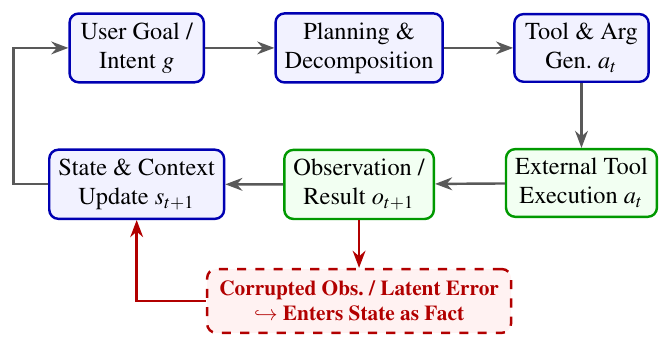

Saved figs/fig1_workflow.pdf and figs/fig1_workflow.png


In [16]:



render_tikz("fig1_workflow", r'''
\documentclass[border=4pt]{standalone}
\usepackage{mathptmx}
\usepackage{amsmath,amssymb,amsfonts}
\usepackage{xcolor}
\usepackage{tikz}
\usetikzlibrary{shapes.geometric, arrows.meta, positioning, calc, fit}
\begin{document}
\begin{tikzpicture}[
    node distance=0.75cm and 0.80cm,
    box/.style={rectangle, draw=blue!70!black, fill=blue!5, rounded corners=3pt,
                thick, align=center, font=\footnotesize,
                minimum height=0.6cm, minimum width=1.55cm, inner sep=3pt},
    actionbox/.style={rectangle, draw=green!60!black, fill=green!5, rounded corners=3pt,
                      thick, align=center, font=\footnotesize,
                      minimum height=0.6cm, minimum width=1.55cm, inner sep=3pt},
    warnbox/.style={rectangle, draw=red!70!black, fill=red!5, rounded corners=3pt,
                    thick, dashed, align=center, font=\scriptsize\bfseries,
                    text=red!70!black, minimum width=3.4cm, inner sep=4pt},
    arrow/.style={-{Stealth[scale=0.85]}, thick, draw=gray!70!black},
    warnarrow/.style={-{Stealth[scale=0.85]}, thick, draw=red!70!black}
]
  \node[box] (goal)   {User Goal /\\ Intent $g$};
  \node[box, right=of goal]   (plan)   {Planning \&\\ Decomposition};
  \node[box, right=of plan]   (select) {Tool \& Arg\\ Gen.\ $a_t$};
  \node[actionbox, below=of select] (exec)  {External Tool\\ Execution $a_t$};
  \node[actionbox, below=of plan]   (obs)   {Observation /\\ Result $o_{t+1}$};
  \node[box,       below=of goal]   (state) {State \& Context\\ Update $s_{t+1}$};
  \node[warnbox, below=0.55cm of obs] (err)
    {Corrupted Obs.\ / Latent Error\\
     $\hookrightarrow$ Enters State as Fact};
  \draw[arrow] (goal)   -- (plan);
  \draw[arrow] (plan)   -- (select);
  \draw[arrow] (select) -- (exec);
  \draw[arrow] (exec)   -- (obs);
  \draw[arrow] (obs)    -- (state);
  \draw[arrow] (state.west) -- ++(-0.4,0) |- (goal.west);
  \draw[warnarrow] (obs.south)  -- (err.north);
  \draw[warnarrow] (err.west)   -| (state.south);
\end{tikzpicture}
\end{document}
''')

### Fig. 2 — Six-class failure taxonomy

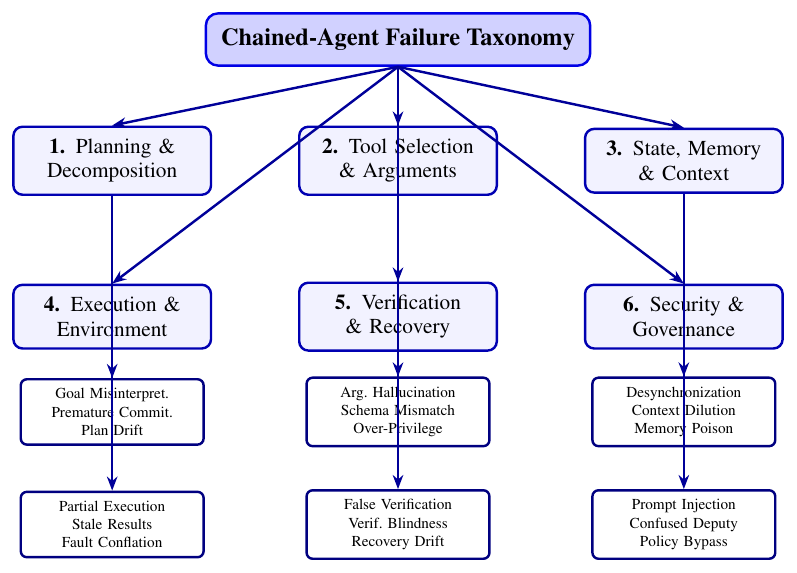

Saved figs/fig2_taxonomy.pdf and figs/fig2_taxonomy.png


In [17]:
render_tikz("fig2_taxonomy", r'''
\documentclass[border=4pt]{standalone}
\usepackage{mathptmx}
\usepackage{amsmath,amssymb,amsfonts}
\usepackage{xcolor}
\usepackage{tikz}
\usetikzlibrary{shapes.geometric, arrows.meta, positioning, calc, fit}
\begin{document}
\begin{tikzpicture}[
  boxstyle/.style={rectangle, draw=blue!70!black, fill=blue!5,
                   rounded corners=3pt, thick, font=\scriptsize,
                   align=center, inner sep=4pt, text width=2.0cm},
  leafstyle/.style={rectangle, draw=blue!50!black, fill=white,
                    rounded corners=2pt, thick, font=\tiny,
                    align=center, inner sep=3pt, text width=1.9cm},
  arrow/.style={-{Stealth[scale=0.7]}, thick, draw=blue!60!black}
]
  \node[rectangle, draw=blue!90!black, fill=blue!18, rounded corners=4pt,
        thick, font=\footnotesize\bfseries, align=center, inner sep=5pt]
    (root) at (3.3, 4.2) {Chained-Agent Failure Taxonomy};
  \node[boxstyle] (c1) at (0.0, 2.8) {\textbf{1.} Planning \&\\ Decomposition};
  \node[boxstyle] (c2) at (3.3, 2.8) {\textbf{2.} Tool Selection\\ \& Arguments};
  \node[boxstyle] (c3) at (6.6, 2.8) {\textbf{3.} State, Memory\\ \& Context};
  \node[boxstyle] (c4) at (0.0, 1.0) {\textbf{4.} Execution \&\\ Environment};
  \node[boxstyle] (c5) at (3.3, 1.0) {\textbf{5.} Verification\\ \& Recovery};
  \node[boxstyle] (c6) at (6.6, 1.0) {\textbf{6.} Security \&\\ Governance};
  \node[leafstyle] (l1) at (0.0,-0.1) {Goal Misinterpret.\\ Premature Commit.\\ Plan Drift};
  \node[leafstyle] (l2) at (3.3,-0.1) {Arg.\ Hallucination\\ Schema Mismatch\\ Over-Privilege};
  \node[leafstyle] (l3) at (6.6,-0.1) {Desynchronization\\ Context Dilution\\ Memory Poison};
  \node[leafstyle] (l4) at (0.0,-1.4) {Partial Execution\\ Stale Results\\ Fault Conflation};
  \node[leafstyle] (l5) at (3.3,-1.4) {False Verification\\ Verif.\ Blindness\\ Recovery Drift};
  \node[leafstyle] (l6) at (6.6,-1.4) {Prompt Injection\\ Confused Deputy\\ Policy Bypass};
  \draw[arrow] (root.south) -- (c1.north);
  \draw[arrow] (root.south) -- (c2.north);
  \draw[arrow] (root.south) -- (c3.north);
  \draw[arrow] (root.south) -- (c4.north);
  \draw[arrow] (root.south) -- (c5.north);
  \draw[arrow] (root.south) -- (c6.north);
  \draw[arrow] (c1.south) -- (l1.north);
  \draw[arrow] (c2.south) -- (l2.north);
  \draw[arrow] (c3.south) -- (l3.north);
  \draw[arrow] (c4.south) -- (l4.north);
  \draw[arrow] (c5.south) -- (l5.north);
  \draw[arrow] (c6.south) -- (l6.north);
\end{tikzpicture}
\end{document}
''')

### Fig. 4 — Task success vs. chain length
This figure in the paper uses **hard-coded data points** (listed in the TikZ comments), not fresh simulation output.

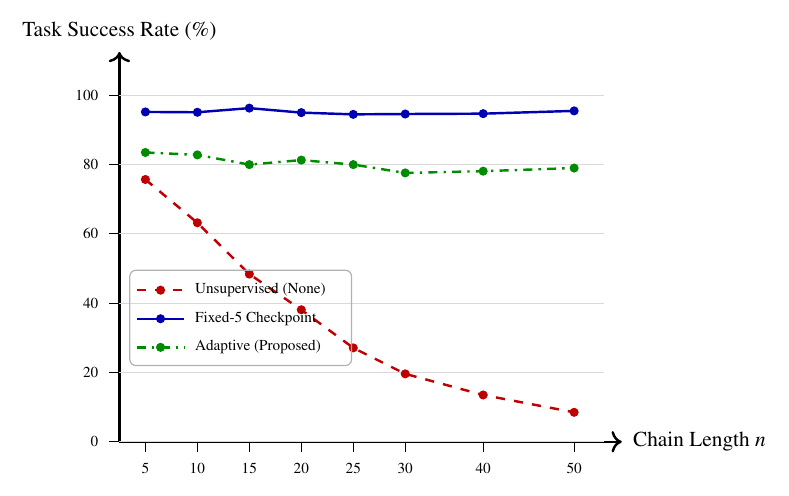

Saved figs/fig4_trajectory_collapse.pdf and figs/fig4_trajectory_collapse.png


In [18]:
render_tikz("fig4_trajectory_collapse", r'''
\documentclass[border=4pt]{standalone}
\usepackage{mathptmx}
\usepackage{amsmath,amssymb,amsfonts}
\usepackage{xcolor}
\usepackage{tikz}
\usetikzlibrary{shapes.geometric, arrows.meta, positioning, calc, fit}
\begin{document}
\begin{tikzpicture}
  \draw[thick,->] (0,0) -- (5.8,0)
    node[right, font=\scriptsize] {Chain Length $n$};
  \draw[thick,->] (0,0) -- (0,4.5)
    node[above, font=\scriptsize] {Task Success Rate (\%)};
  \foreach \y/\lab in {0/0, 0.8/20, 1.6/40, 2.4/60, 3.2/80, 4.0/100}{
    \draw[gray!30] (0,\y) -- (5.6,\y);
    \draw (0,\y) -- (-0.12,\y);
    \node[left, font=\tiny] at (-0.12,\y) {\lab};
  }
  \foreach \x/\lab in {0.3/5, 0.9/10, 1.5/15, 2.1/20, 2.7/25, 3.3/30, 4.2/40, 5.25/50}{
    \draw (\x,0) -- (\x,-0.12);
    \node[below, font=\tiny] at (\x,-0.12) {\lab};
  }
  \draw[red!75!black, thick, dashed]
    (0.30, 3.028) -- (0.90, 2.528) -- (1.50, 1.936) -- (2.10, 1.524) --
    (2.70, 1.084) -- (3.30, 0.784) -- (4.20, 0.540) -- (5.25, 0.340);
  \foreach \x/\y in {0.30/3.028, 0.90/2.528, 1.50/1.936, 2.10/1.524,
                      2.70/1.084, 3.30/0.784, 4.20/0.540, 5.25/0.340}{
    \fill[red!75!black] (\x,\y) circle (1.5pt);
  }
  \draw[blue!70!black, thick]
    (0.30, 3.808) -- (0.90, 3.804) -- (1.50, 3.852) -- (2.10, 3.800) --
    (2.70, 3.780) -- (3.30, 3.784) -- (4.20, 3.788) -- (5.25, 3.820);
  \foreach \x/\y in {0.30/3.808, 0.90/3.804, 1.50/3.852, 2.10/3.800,
                      2.70/3.780, 3.30/3.784, 4.20/3.788, 5.25/3.820}{
    \fill[blue!70!black] (\x,\y) circle (1.5pt);
  }
  \draw[green!55!black, thick, dash dot]
    (0.30, 3.340) -- (0.90, 3.312) -- (1.50, 3.200) -- (2.10, 3.252) --
    (2.70, 3.200) -- (3.30, 3.104) -- (4.20, 3.124) -- (5.25, 3.160);
  \foreach \x/\y in {0.30/3.340, 0.90/3.312, 1.50/3.200, 2.10/3.252,
                      2.70/3.200, 3.30/3.104, 4.20/3.124, 5.25/3.160}{
    \fill[green!55!black] (\x,\y) circle (1.5pt);
  }
  \draw[red!75!black, thick, dashed]  (0.2, 1.75) -- (0.75, 1.75);
  \fill[red!75!black] (0.475,1.75) circle (1.5pt);
  \node[right, font=\tiny] at (0.75, 1.75) {Unsupervised (None)};
  \draw[blue!70!black, thick]         (0.2, 1.42) -- (0.75, 1.42);
  \fill[blue!70!black] (0.475,1.42) circle (1.5pt);
  \node[right, font=\tiny] at (0.75, 1.42) {Fixed-5 Checkpoint};
  \draw[green!55!black, thick, dash dot] (0.2, 1.09) -- (0.75, 1.09);
  \fill[green!55!black] (0.475,1.09) circle (1.5pt);
  \node[right, font=\tiny] at (0.75, 1.09) {Adaptive (Proposed)};
  \draw[gray!60, thin, rounded corners=2pt] (0.12, 0.88) rectangle (2.68, 1.98);
\end{tikzpicture}
\end{document}
''')

### Simulation-driven version of Fig. 4 (matplotlib)
Same styling, but plotted from the Monte Carlo run in section 5, so you can compare it with the paper's hard-coded curve.

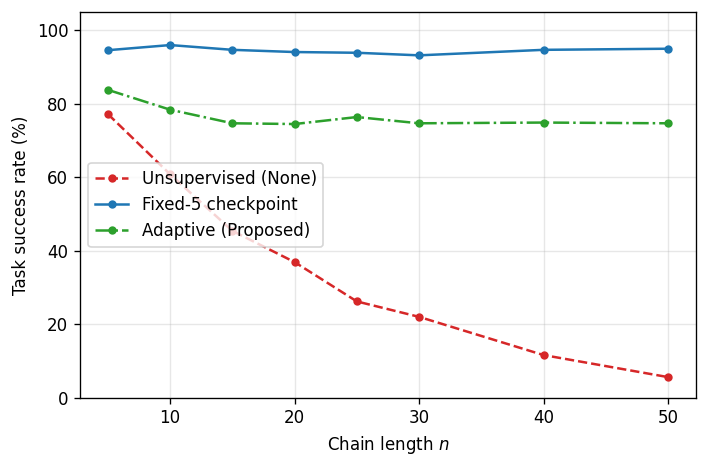

In [19]:
fig, ax = plt.subplots(figsize=(6,4))
style = {"none":("Unsupervised (None)","tab:red","--"),
         "fixed5":("Fixed-5 checkpoint","tab:blue","-"),
         "adaptive":("Adaptive (Proposed)","tab:green","-.")}
for m,(lab,c,ls) in style.items():
    d = df[df["mode"]==m]
    ax.plot(d["n"], d["success_pct"], ls, color=c, marker="o", ms=4, label=lab)
ax.set_xlabel("Chain length $n$"); ax.set_ylabel("Task success rate (%)")
ax.set_ylim(0,105); ax.grid(alpha=.3); ax.legend(loc="center left")
plt.tight_layout(); plt.savefig("trajectory_collapse.png", dpi=300); plt.show()

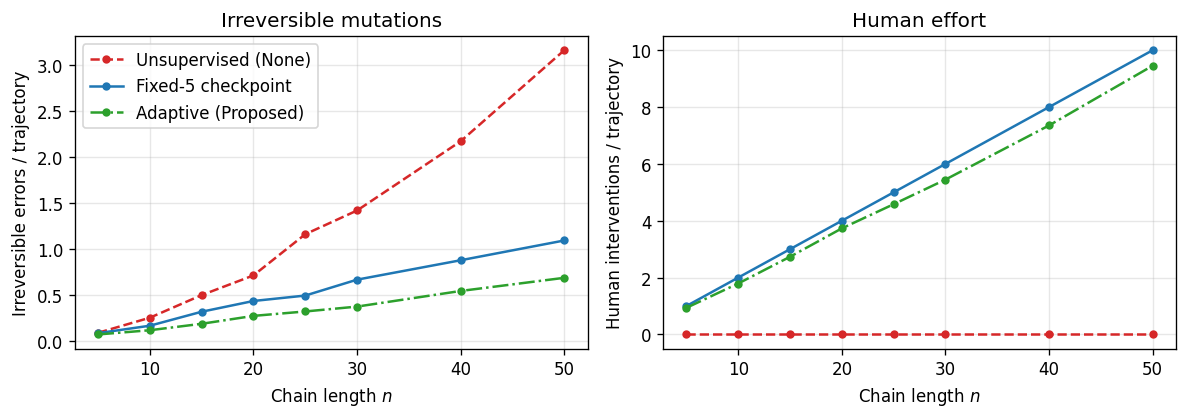

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10,3.6))
for m,(lab,c,ls) in style.items():
    d = df[df["mode"]==m]
    axes[0].plot(d["n"], d["irreversible_per_traj"], ls, color=c, marker="o", ms=4, label=lab)
    axes[1].plot(d["n"], d["human_interventions"],   ls, color=c, marker="o", ms=4, label=lab)
axes[0].set(xlabel="Chain length $n$", ylabel="Irreversible errors / trajectory", title="Irreversible mutations")
axes[1].set(xlabel="Chain length $n$", ylabel="Human interventions / trajectory", title="Human effort")
for a in axes: a.grid(alpha=.3)
axes[0].legend(); plt.tight_layout(); plt.show()

## 7. Headline numbers quoted in the paper

In [21]:
g = df.set_index(["n","mode"])
n50 = 50
none, fix, ada = g.loc[(n50,"none")], g.loc[(n50,"fixed5")], g.loc[(n50,"adaptive")]
print(f"n=50 success:  none {none.success_pct:.1f}%  fixed-5 {fix.success_pct:.1f}%  adaptive {ada.success_pct:.1f}%")
print(f"Irreversible errors/traj growth n=5 -> n=50 (none): "
      f"{g.loc[(50,'none')].irreversible_per_traj / g.loc[(5,'none')].irreversible_per_traj:.1f}x")
print(f"Irreversible reduction, adaptive vs none @n=50: "
      f"{none.irreversible_per_traj/ada.irreversible_per_traj:.1f}x  "
      f"({100*(1-ada.irreversible_per_traj/none.irreversible_per_traj):.1f}% fewer)")
print(f"Adaptive success range across horizons: "
      f"{df[df['mode']=='adaptive'].success_pct.min():.1f}% - {df[df['mode']=='adaptive'].success_pct.max():.1f}%")
sav = 1 - (df[df['mode']=='adaptive'].human_interventions.values /
           df[df['mode']=='fixed5'].human_interventions.values)
print(f"Human-effort saving vs fixed-5 (mean over horizons): {100*sav.mean():.1f}%")

n=50 success:  none 5.6%  fixed-5 95.0%  adaptive 74.7%
Irreversible errors/traj growth n=5 -> n=50 (none): 35.9x
Irreversible reduction, adaptive vs none @n=50: 4.6x  (78.3% fewer)
Adaptive success range across horizons: 74.5% - 83.8%
Human-effort saving vs fixed-5 (mean over horizons): 7.9%


> **Check before submitting.** The paper's text says adaptive reduces irreversible errors by *83.5 %* and by *6×*; those are two different figures for the same quantity (6× ≈ 83 % reduction, so they agree), but the 83.5 % also coincides with the adaptive success rate at n=5, which looks accidental. Also, the Key Observation says success *"improves … (77.6 % to 83.5 %)"*, which describes the adaptive range rather than an improvement. Cell 7 prints the figures actually produced, so you can make the text match the table.

## 8. Reliability vector (Eq. 5) — scoring skeleton

In [22]:
from dataclasses import dataclass, asdict
@dataclass
class ReliabilityVector:
    R_success: float; R_traj: float; R_policy: float
    R_state: float;   R_sec: float;  R_recov: float; R_consist: float  # R_consist = pass^k

def pass_k(successes_per_task, k):
    # successes_per_task: array of shape (tasks, trials) of 0/1; tau-bench style pass^k
    s = np.asarray(successes_per_task); c = s.sum(1); m = s.shape[1]
    from math import comb
    return np.mean([comb(int(ci), k)/comb(m, k) for ci in c])

rng = np.random.default_rng(0)
demo = (rng.random((200, 8)) < 0.7).astype(int)
print({f"pass^{k}": round(pass_k(demo, k), 3) for k in (1, 2, 4, 8)})

{'pass^1': np.float64(0.686), 'pass^2': np.float64(0.472), 'pass^4': np.float64(0.227), 'pass^8': np.float64(0.05)}


## 9. (Optional) Compile the LaTeX paper in Colab
Upload your `.tex` file (and `references.bib` if you have it). The first cell installs TeX Live (~2–4 min).

In [23]:
!apt-get -qq update && apt-get -qq install -y texlive-latex-recommended texlive-latex-extra texlive-fonts-recommended texlive-publishers texlive-science biber > /dev/null
!ls $(kpsewhich IEEEtran.cls) && echo "IEEEtran OK"

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
/usr/share/texlive/texmf-dist/tex/latex/ieeetran/IEEEtran.cls
IEEEtran OK


In [ ]:
from google.colab import files
up = files.upload()           # select your .tex (and references.bib)
tex = [f for f in up if f.endswith(".tex")][0]
stem = tex[:-4]
!pdflatex -interaction=nonstopmode {tex} > /dev/null
!bibtex {stem} > /dev/null 2>&1 || true
!pdflatex -interaction=nonstopmode {tex} > /dev/null
!pdflatex -interaction=nonstopmode {tex} | tail -n 5
files.download(stem + ".pdf")